# Human vs. Model Difficulty Correlation

For each image in the occluded condition, we compute **human accuracy** (fraction of Prolific respondents who answered correctly) and check whether models also struggle on the same images.

Judge correctness uses **either** GPT-5.4 or Claude Opus 4-6 agreeing (same convention as the token-length notebooks).

In [ ]:
# Run from the repo root so the root-relative data paths below resolve
import os
from pathlib import Path
os.chdir(next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "sec3_occludebench").is_dir()))

In [1]:
import json
import numpy as np
import pandas as pd
import matplotlib as mpl
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import seaborn as sns  # colour palette only
from scipy import stats
from pathlib import Path
from collections import defaultdict
import warnings
warnings.filterwarnings('ignore')

mpl.rcParams.update({
    'font.family':       'Arial',
    'font.size':         9,
    'axes.titlesize':    10,
    'axes.labelsize':    9,
    'xtick.labelsize':   9,
    'ytick.labelsize':   9,
    'legend.fontsize':   9,
    'axes.titleweight':  'normal',
    'axes.grid':         False,
    'axes.spines.top':   False,
    'axes.spines.right': False,
    'figure.dpi':        150,
})

ROOT = Path('.')
EVAL_DIR  = ROOT / 'data/eval_results'
HUMAN_DIR = ROOT / 'data/eval_results_human'

## 1. Load Data

In [2]:
# --- Human accuracy per image ---
with open(HUMAN_DIR / 'human_prolific_judged_results.json') as f:
    human_raw = json.load(f)

human_by_image = defaultdict(list)
for r in human_raw:
    human_by_image[str(r['image_id'])].append(r['consensus_correct'])

human_acc = {
    img_id: sum(vals) / len(vals)
    for img_id, vals in human_by_image.items()
}
human_n = {img_id: len(vals) for img_id, vals in human_by_image.items()}

print(f'Images with human data: {len(human_acc)}')
print(f'Total human responses:  {len(human_raw)}')
print(f'Avg respondents/image:  {np.mean(list(human_n.values())):.1f}')
print(f'Overall human accuracy: {np.mean(list(human_acc.values())):.3f}')

Images with human data: 378
Total human responses:  2239
Avg respondents/image:  5.9
Overall human accuracy: 0.654


In [3]:
# --- Model accuracy per image ---
MODELS = [
    'gpt-5.4',
    'claude-opus-4-6',
    'gemini-3.1-pro-preview',
    'Qwen3-VL-8B-Instruct',
    'Llama-4-Maverick-17B-128E-Instruct-FP8-9940db5c',
]
DISPLAY = {
    'claude-opus-4-6':                                   'Claude Opus 4.6',
    'gemini-3.1-pro-preview':                            'Gemini 3.1 Pro',
    'gpt-5.4':                                           'GPT-5.4',
    'Llama-4-Maverick-17B-128E-Instruct-FP8-9940db5c':  'Llama 4 Maverick',
    'Qwen3-VL-8B-Instruct':                              'Qwen 3 VL 8B',
}
MODEL_ORDER = [DISPLAY[m] for m in MODELS]
PALETTE = {
    'Claude Opus 4.6':  '#DD8452',
    'Gemini 3.1 Pro':   '#55A868',
    'GPT-5.4':          '#4C72B0',
    'Llama 4 Maverick': '#8172B3',
    'Qwen 3 VL 8B':     '#C44E52',
}

rows = []
for model in MODELS:
    with open(EVAL_DIR / f'{model}_judged_results.json') as f:
        data = json.load(f)
    for entry in data:
        img_id = str(entry['id'])
        occ_j  = entry.get('occluded_correct', {})
        correct = any(occ_j.values()) if occ_j else False
        rows.append({
            'image_id':    img_id,
            'model':       model,
            'model_short': DISPLAY[model],
            'correct':     correct,
            'human_acc':   human_acc.get(img_id, np.nan),
            'human_n':     human_n.get(img_id, 0),
        })

df = pd.DataFrame(rows).dropna(subset=['human_acc'])
print(df.groupby('model_short')['correct'].mean().reindex(MODEL_ORDER).round(3))
print(f'\nImages with both human + model data: {df["image_id"].nunique()}')

model_short
GPT-5.4             0.495
Claude Opus 4.6     0.630
Gemini 3.1 Pro      0.794
Qwen 3 VL 8B        0.332
Llama 4 Maverick    0.366
Name: correct, dtype: float64

Images with both human + model data: 378


## 2. Point-Biserial Correlation: Human Accuracy ↔ Model Correctness

Positive r means models are more likely to be correct on images humans also find easy.

           Model        r            p sig
         GPT-5.4 0.323347 1.198104e-10 ***
 Claude Opus 4.6 0.281898 2.460176e-08 ***
  Gemini 3.1 Pro 0.363804 2.847188e-13 ***
    Qwen 3 VL 8B 0.249228 9.554078e-07 ***
Llama 4 Maverick 0.283505 2.122114e-08 ***


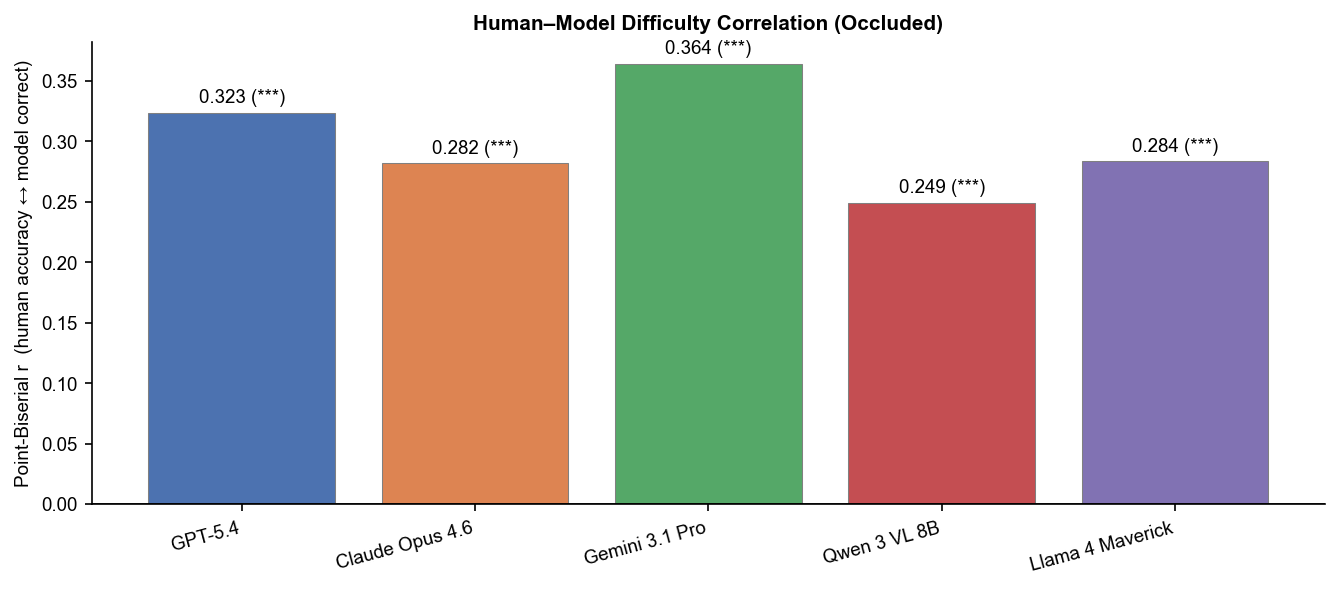

In [4]:
corr_rows = []
for model in MODELS:
    sub = df[df['model'] == model][['human_acc', 'correct']].dropna()
    r, p = stats.pointbiserialr(sub['correct'].astype(int), sub['human_acc'])
    corr_rows.append({
        'Model': DISPLAY[model],
        'r':     r,
        'p':     p,
        'sig':   '***' if p < 0.001 else '**' if p < 0.01 else '*' if p < 0.05 else 'ns',
    })

corr_df = pd.DataFrame(corr_rows)
print(corr_df.to_string(index=False))

fig, ax = plt.subplots(figsize=(9, 4))
colors = [PALETTE[DISPLAY[m]] for m in MODELS]
bars = ax.bar(corr_df['Model'], corr_df['r'], color=colors, edgecolor='grey', lw=0.5)
for bar, row in zip(bars, corr_df.itertuples()):
    yoff = 0.005 if row.r >= 0 else -0.015
    ax.text(bar.get_x() + bar.get_width() / 2, bar.get_height() + yoff,
            f'{row.r:.3f} ({row.sig})', ha='center', va='bottom', fontsize=9)
ax.axhline(0, color='black', lw=0.8)
ax.set_ylabel('Point-Biserial r  (human accuracy ↔ model correct)')
ax.set_title('Human–Model Difficulty Correlation (Occluded)', fontweight='bold')
ax.set_xticklabels(corr_df['Model'], rotation=15, ha='right')
plt.tight_layout()
plt.savefig('data/figures/human_model_corr_point_biserial.pdf', bbox_inches='tight')
plt.show()

## 3. Model Accuracy by Human-Difficulty Quintile

Images are split into 5 equal-sized bins by human accuracy (Q1 = hardest for humans, Q5 = easiest). We then plot model accuracy within each bin.

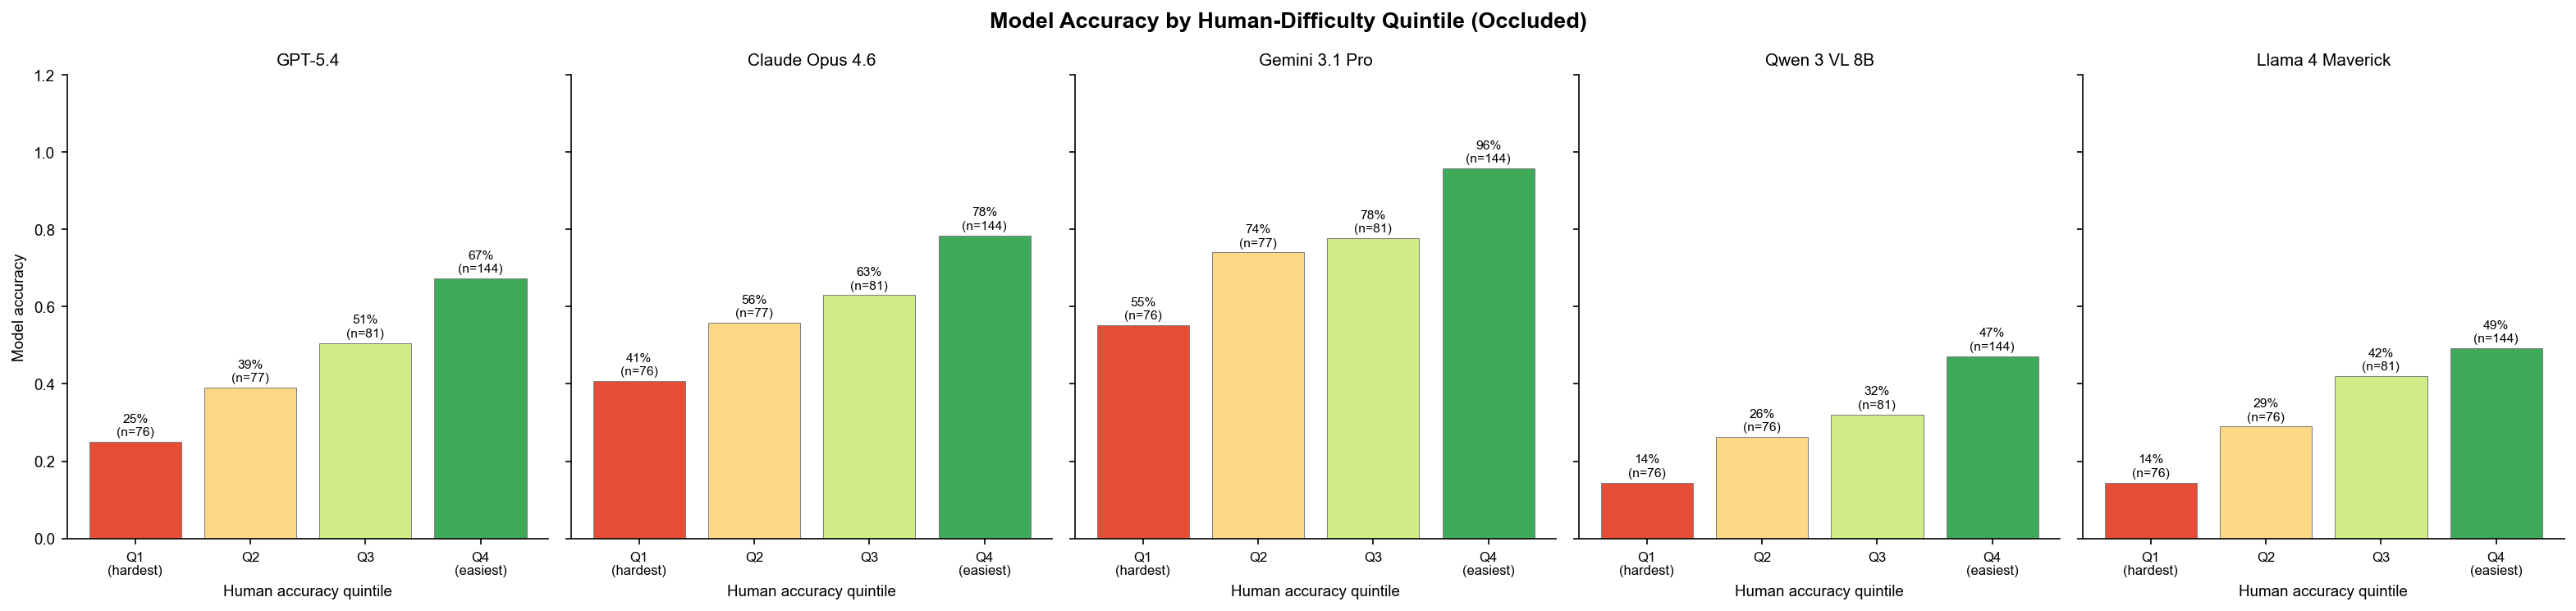

In [5]:

# Assign quintiles based on human accuracy (same bins for all models)
# Note: many images have human_acc == 1.0 so qcut collapses to 4 unique bins
image_df = df[df['model'] == MODELS[0]][['image_id', 'human_acc']].drop_duplicates().copy()
image_df['quintile'], bin_edges = pd.qcut(
    image_df['human_acc'], q=5, retbins=True, duplicates='drop'
)
n_bins = len(bin_edges) - 1

# Build short labels: Q1=(hardest)..Qn=(easiest)
bin_cats   = image_df['quintile'].cat.categories.tolist()
short_labels = [f'Q{i+1}' for i in range(n_bins)]
short_labels[0]  += '\n(hardest)'
short_labels[-1] += '\n(easiest)'
cat_to_short = dict(zip(bin_cats, short_labels))
image_df['q_label'] = image_df['quintile'].map(cat_to_short)

df = df.merge(image_df[['image_id', 'quintile', 'q_label']], on='image_id', how='left')

fig, axes = plt.subplots(1, len(MODELS), figsize=(4.2 * len(MODELS), 5), sharey=True)
fig.suptitle('Model Accuracy by Human-Difficulty Quintile (Occluded)',
             fontsize=13, fontweight='bold')

for ax, model in zip(axes, MODELS):
    sub = df[df['model'] == model].copy()
    agg = (sub.groupby('q_label', observed=True)['correct']
              .agg(['mean', 'count'])
              .reindex(short_labels))
    colors = plt.cm.RdYlGn(np.linspace(0.15, 0.85, len(agg)))
    bars = ax.bar(short_labels, agg['mean'], color=colors, edgecolor='grey', lw=0.5)
    for bar, row in zip(bars, agg.itertuples()):
        ax.text(bar.get_x() + bar.get_width() / 2, bar.get_height() + 0.01,
                f'{row.mean:.0%}\n(n={row.count})', ha='center', va='bottom', fontsize=7.5)
    ax.set_ylim(0, 1.2)
    ax.set_title(DISPLAY[model], fontsize=10)
    ax.set_xlabel('Human accuracy quintile')
    if ax is axes[0]:
        ax.set_ylabel('Model accuracy')
    ax.tick_params(axis='x', labelsize=8)

plt.tight_layout()
plt.savefig('data/figures/human_model_corr_accuracy_by_quintile.pdf', bbox_inches='tight')
plt.show()


## 4. Scatter: Human Accuracy vs. Model Accuracy (Per Image)

Each dot is one image. x = fraction of humans correct, y = model's binary 0/1 (jittered). Logistic regression curve overlaid.

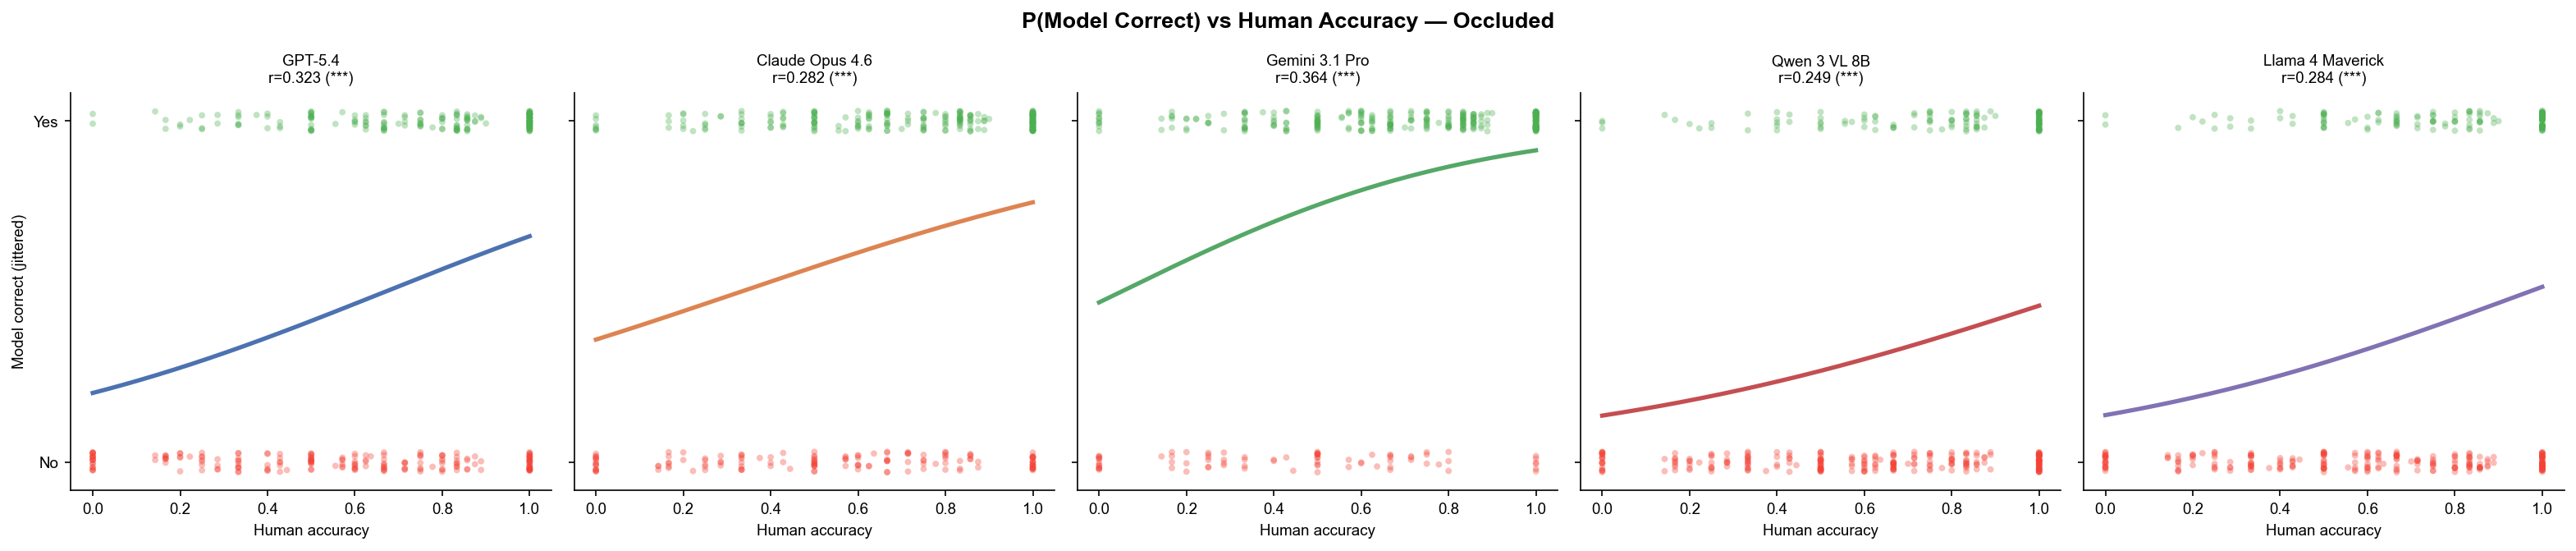

In [6]:
from sklearn.linear_model import LogisticRegression

rng = np.random.default_rng(42)
fig, axes = plt.subplots(1, len(MODELS), figsize=(4.2 * len(MODELS), 4.5), sharey=True)
fig.suptitle('P(Model Correct) vs Human Accuracy — Occluded', fontsize=13, fontweight='bold')

for ax, model in zip(axes, MODELS):
    sub = df[df['model'] == model][['human_acc', 'correct']].dropna().copy()
    X = sub['human_acc'].values
    y = sub['correct'].astype(int).values
    jitter = rng.uniform(-0.03, 0.03, len(y))
    point_colors = ['#4CAF50' if c else '#F44336' for c in y]
    ax.scatter(X, y + jitter, c=point_colors, alpha=0.35, s=14, edgecolors='none')

    lr = LogisticRegression()
    lr.fit(X.reshape(-1, 1), y)
    xr = np.linspace(0, 1, 200)
    ph = lr.predict_proba(xr.reshape(-1, 1))[:, 1]
    ax.plot(xr, ph, color=PALETTE[DISPLAY[model]], lw=2.5)

    r, p = stats.pointbiserialr(y, X)
    sig = '***' if p < 0.001 else '**' if p < 0.01 else '*' if p < 0.05 else 'ns'
    ax.set_title(f'{DISPLAY[model]}\nr={r:.3f} ({sig})', fontsize=9)
    ax.set_xlabel('Human accuracy')
    ax.set_xlim(-0.05, 1.05)
    if ax is axes[0]:
        ax.set_ylabel('Model correct (jittered)')
    ax.set_yticks([0, 1])
    ax.set_yticklabels(['No', 'Yes'])

plt.tight_layout()
plt.savefig('data/figures/human_model_corr_scatter_logistic.pdf', bbox_inches='tight')
plt.show()

## 5. Combined Accuracy by Human-Difficulty Bin (All Models)

A single panel showing all models together, binned by human accuracy decile. Also shows the human baseline in each bin.

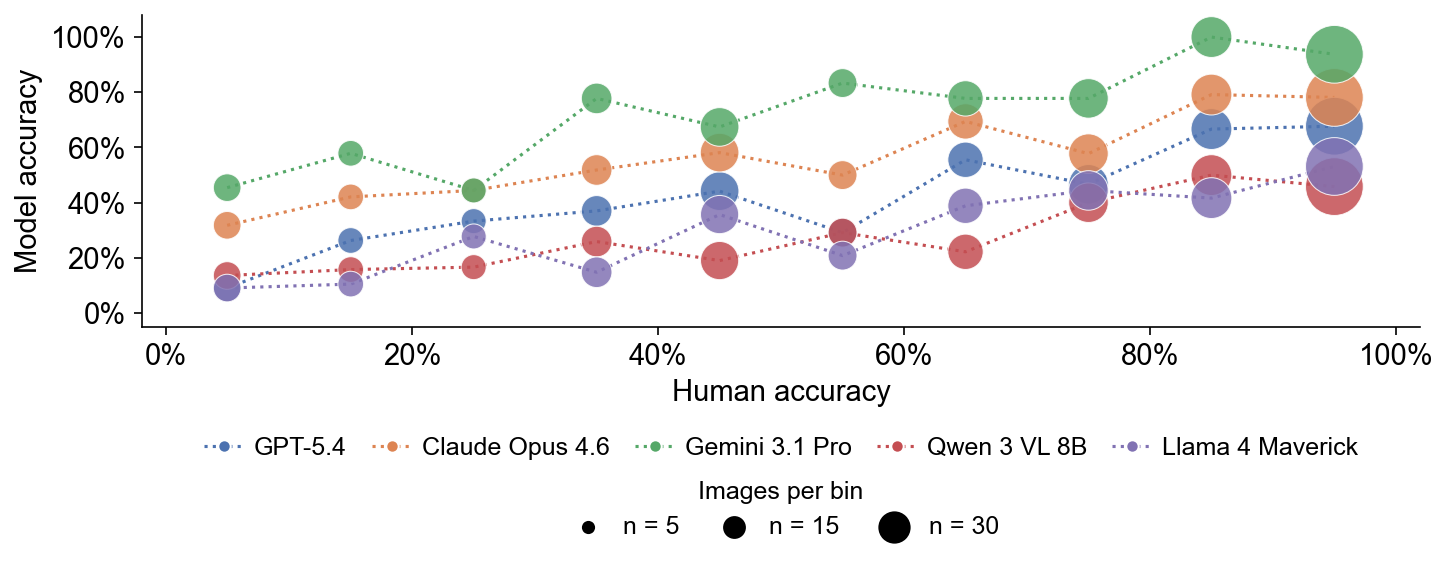

In [7]:
from matplotlib.lines import Line2D

# Build per-image pivot
pivot = df.pivot_table(index='image_id', columns='model_short', values='correct', aggfunc='first')
pivot['human_acc'] = pivot.index.map(human_acc)
pivot = pivot.dropna(subset=['human_acc'])

# Bin by human accuracy (10% bins) for the dots
BIN_W = 0.1
bins = np.arange(0, 1 + BIN_W, BIN_W)
pivot['bin_mid'] = pd.cut(pivot['human_acc'], bins=bins, include_lowest=True).apply(
    lambda iv: iv.mid * 100 if pd.notna(iv) else np.nan
)

fig, ax = plt.subplots(figsize=(11, 4.0))

model_handles = []
for model in MODEL_ORDER:
    color = PALETTE[model]
    model_data = pivot[['human_acc', 'bin_mid', model]].dropna()

    agg = model_data.groupby('bin_mid')[model].agg(['mean', 'count']).reset_index()
    agg = agg[agg['count'] >= 3]
    ax.scatter(agg['bin_mid'], agg['mean'] * 100,
               s=agg['count'] * 8, color=color, alpha=0.85,
               edgecolors='white', linewidths=0.5, zorder=3)

    ax.plot(agg['bin_mid'], agg['mean'] * 100, color=color, lw=1.5,
            linestyle=':', zorder=2)

    model_handles.append(
        Line2D([0], [0], color=color, lw=1.5, linestyle=':', marker='o', markersize=6,
               markerfacecolor=color, markeredgecolor='white', label=model)
    )

ax.set_xlim(-2, 102)
ax.set_ylim(-5, 108)
ax.set_xticks([0, 20, 40, 60, 80, 100])
ax.set_yticks([0, 20, 40, 60, 80, 100])
ax.minorticks_off()
ax.tick_params(axis='both', which='major', direction='out', length=4, labelsize=14)
ax.set_xlabel('Human accuracy', fontsize=14)
ax.set_ylabel('Model accuracy', fontsize=14)
ax.xaxis.set_major_formatter(mtick.PercentFormatter())
ax.yaxis.set_major_formatter(mtick.PercentFormatter())

ref_ns = [5, 15, 30]
ref_handles = [
    plt.scatter([], [], s=n * 8, color='black', alpha=1.0,
                edgecolors='black', linewidths=0, label=f'n = {n}')
    for n in ref_ns
]

plt.subplots_adjust(bottom=0.36)

# Row 1: model line+dot handles
leg1 = ax.legend(handles=model_handles,
                 labels=[h.get_label() for h in model_handles],
                 loc='upper center', bbox_to_anchor=(0.5, -0.28),
                 ncol=len(model_handles), frameon=False,
                 fontsize=12, columnspacing=1.0,
                 handlelength=1.6, handletextpad=0.4)
ax.add_artist(leg1)

# Row 2: bubble size indicators
ax.legend(handles=ref_handles,
          labels=[f'n = {n}' for n in ref_ns],
          loc='upper center', bbox_to_anchor=(0.5, -0.42),
          ncol=len(ref_handles), frameon=False,
          title='Images per bin', title_fontsize=12,
          fontsize=12, columnspacing=1.2, handletextpad=0.4)

plt.savefig('data/figures/human_model_corr_combined_dots.pdf', bbox_inches='tight')
plt.show()


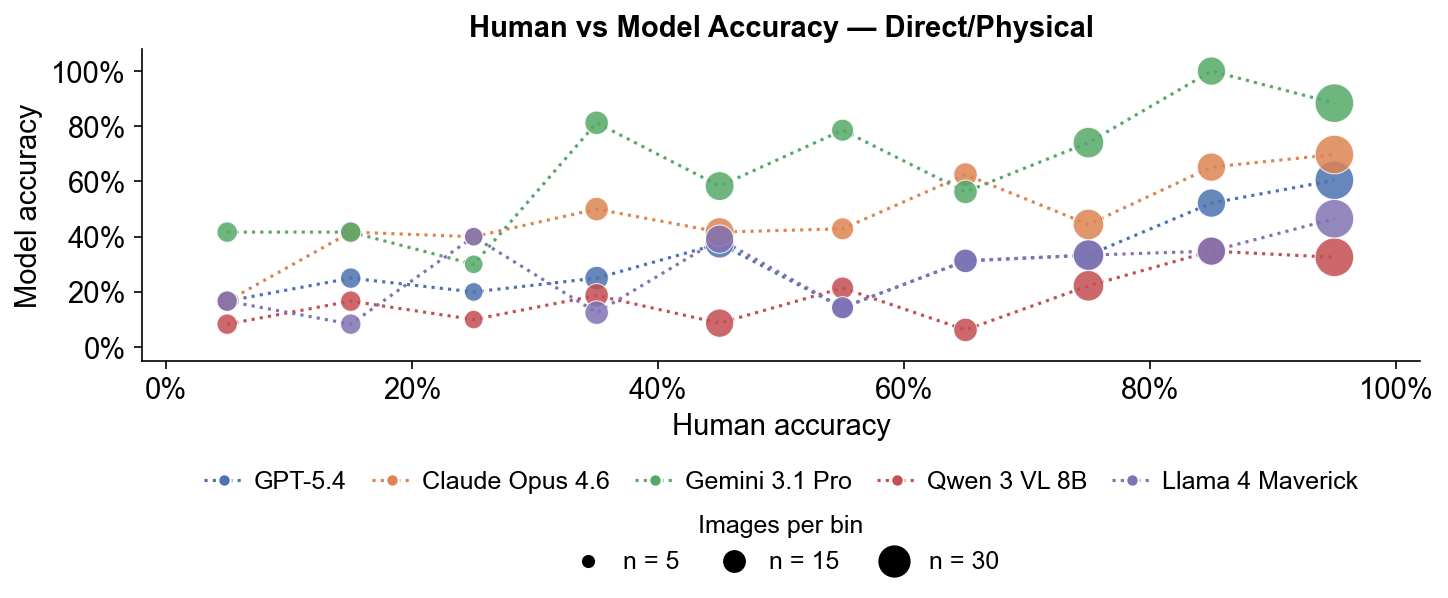

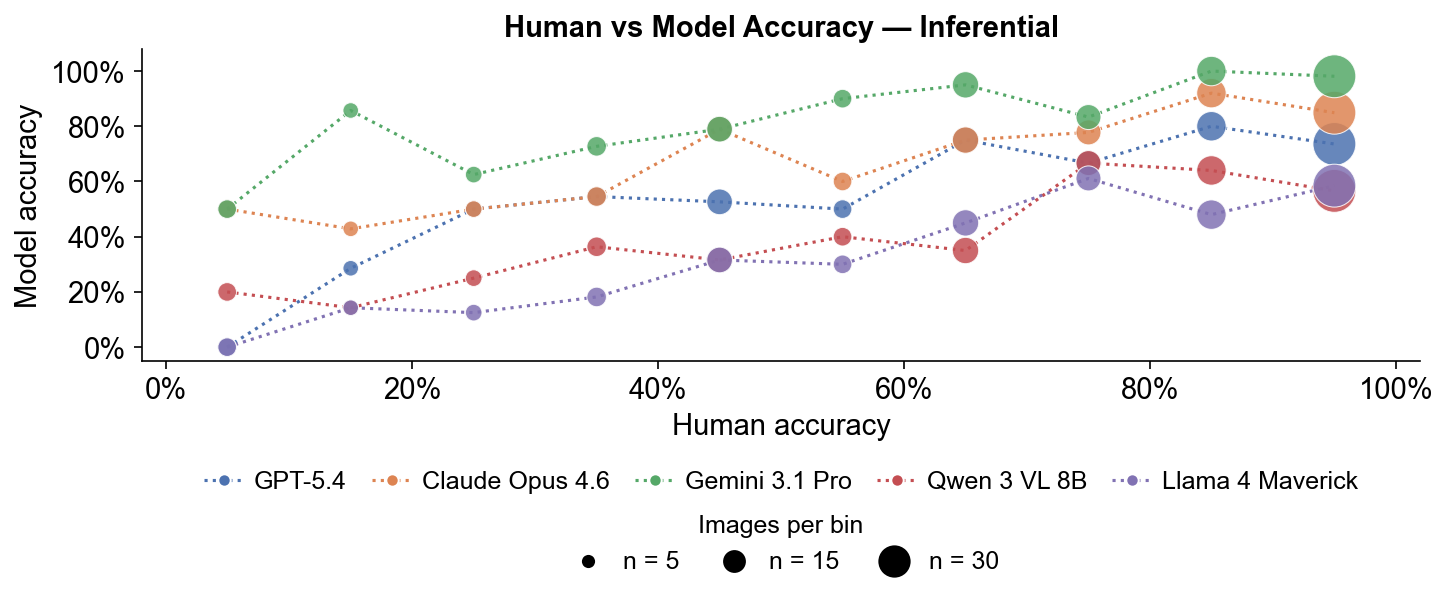

In [8]:
# ---- Same combined dot-plot, split into DIRECT/PHYSICAL and INFERENTIAL ----
# Category label per image from the manual "direct or inferential" annotations
# (in this dataset direct == physically-occluded, inferential == digitally-occluded).
_cat = pd.read_excel(ROOT / 'data/Image categories (3).xlsx')[['image id', 'direct or inferential']]
_cat['image id'] = _cat['image id'].astype(str)
img_cat = dict(zip(_cat['image id'], _cat['direct or inferential']))

# Rebuild the pivot with a category column (reuses the human-accuracy binning above)
pivot_cat = df.pivot_table(index='image_id', columns='model_short', values='correct', aggfunc='first')
pivot_cat['human_acc'] = pivot_cat.index.map(human_acc)
pivot_cat['category']  = pivot_cat.index.map(img_cat)
pivot_cat = pivot_cat.dropna(subset=['human_acc'])
pivot_cat['bin_mid'] = pd.cut(pivot_cat['human_acc'], bins=bins, include_lowest=True).apply(
    lambda iv: iv.mid * 100 if pd.notna(iv) else np.nan
)


def plot_human_model_dots(sub, title, outfile):
    fig, ax = plt.subplots(figsize=(11, 4.0))
    model_handles = []
    for model in MODEL_ORDER:
        color = PALETTE[model]
        model_data = sub[['human_acc', 'bin_mid', model]].dropna()
        agg = model_data.groupby('bin_mid')[model].agg(['mean', 'count']).reset_index()
        agg = agg[agg['count'] >= 3]
        ax.scatter(agg['bin_mid'], agg['mean'] * 100,
                   s=agg['count'] * 8, color=color, alpha=0.85,
                   edgecolors='white', linewidths=0.5, zorder=3)
        ax.plot(agg['bin_mid'], agg['mean'] * 100, color=color, lw=1.5,
                linestyle=':', zorder=2)
        model_handles.append(
            Line2D([0], [0], color=color, lw=1.5, linestyle=':', marker='o', markersize=6,
                   markerfacecolor=color, markeredgecolor='white', label=model)
        )

    ax.set_xlim(-2, 102)
    ax.set_ylim(-5, 108)
    ax.set_xticks([0, 20, 40, 60, 80, 100])
    ax.set_yticks([0, 20, 40, 60, 80, 100])
    ax.minorticks_off()
    ax.tick_params(axis='both', which='major', direction='out', length=4, labelsize=14)
    ax.set_xlabel('Human accuracy', fontsize=14)
    ax.set_ylabel('Model accuracy', fontsize=14)
    ax.set_title(title, fontsize=14, fontweight='bold')
    ax.xaxis.set_major_formatter(mtick.PercentFormatter())
    ax.yaxis.set_major_formatter(mtick.PercentFormatter())

    ref_ns = [5, 15, 30]
    ref_handles = [
        plt.scatter([], [], s=n * 8, color='black', alpha=1.0,
                    edgecolors='black', linewidths=0, label=f'n = {n}')
        for n in ref_ns
    ]

    plt.subplots_adjust(bottom=0.36)
    leg1 = ax.legend(handles=model_handles, labels=[h.get_label() for h in model_handles],
                     loc='upper center', bbox_to_anchor=(0.5, -0.28),
                     ncol=len(model_handles), frameon=False, fontsize=12,
                     columnspacing=1.0, handlelength=1.6, handletextpad=0.4)
    ax.add_artist(leg1)
    ax.legend(handles=ref_handles, labels=[f'n = {n}' for n in ref_ns],
              loc='upper center', bbox_to_anchor=(0.5, -0.42),
              ncol=len(ref_handles), frameon=False, title='Images per bin',
              title_fontsize=12, fontsize=12, columnspacing=1.2, handletextpad=0.4)
    plt.savefig(outfile, bbox_inches='tight')
    plt.show()


plot_human_model_dots(
    pivot_cat[pivot_cat['category'] == 'direct'],
    'Human vs Model Accuracy — Direct/Physical',
    'data/figures/human_model_corr_combined_dots_direct.pdf')

plot_human_model_dots(
    pivot_cat[pivot_cat['category'] == 'inferential'],
    'Human vs Model Accuracy — Inferential',
    'data/figures/human_model_corr_combined_dots_inferential.pdf')


## 6. Hardest-for-Humans Images: Do All Models Fail Together?

For images where human accuracy < 20%, what fraction do ALL models get wrong simultaneously?

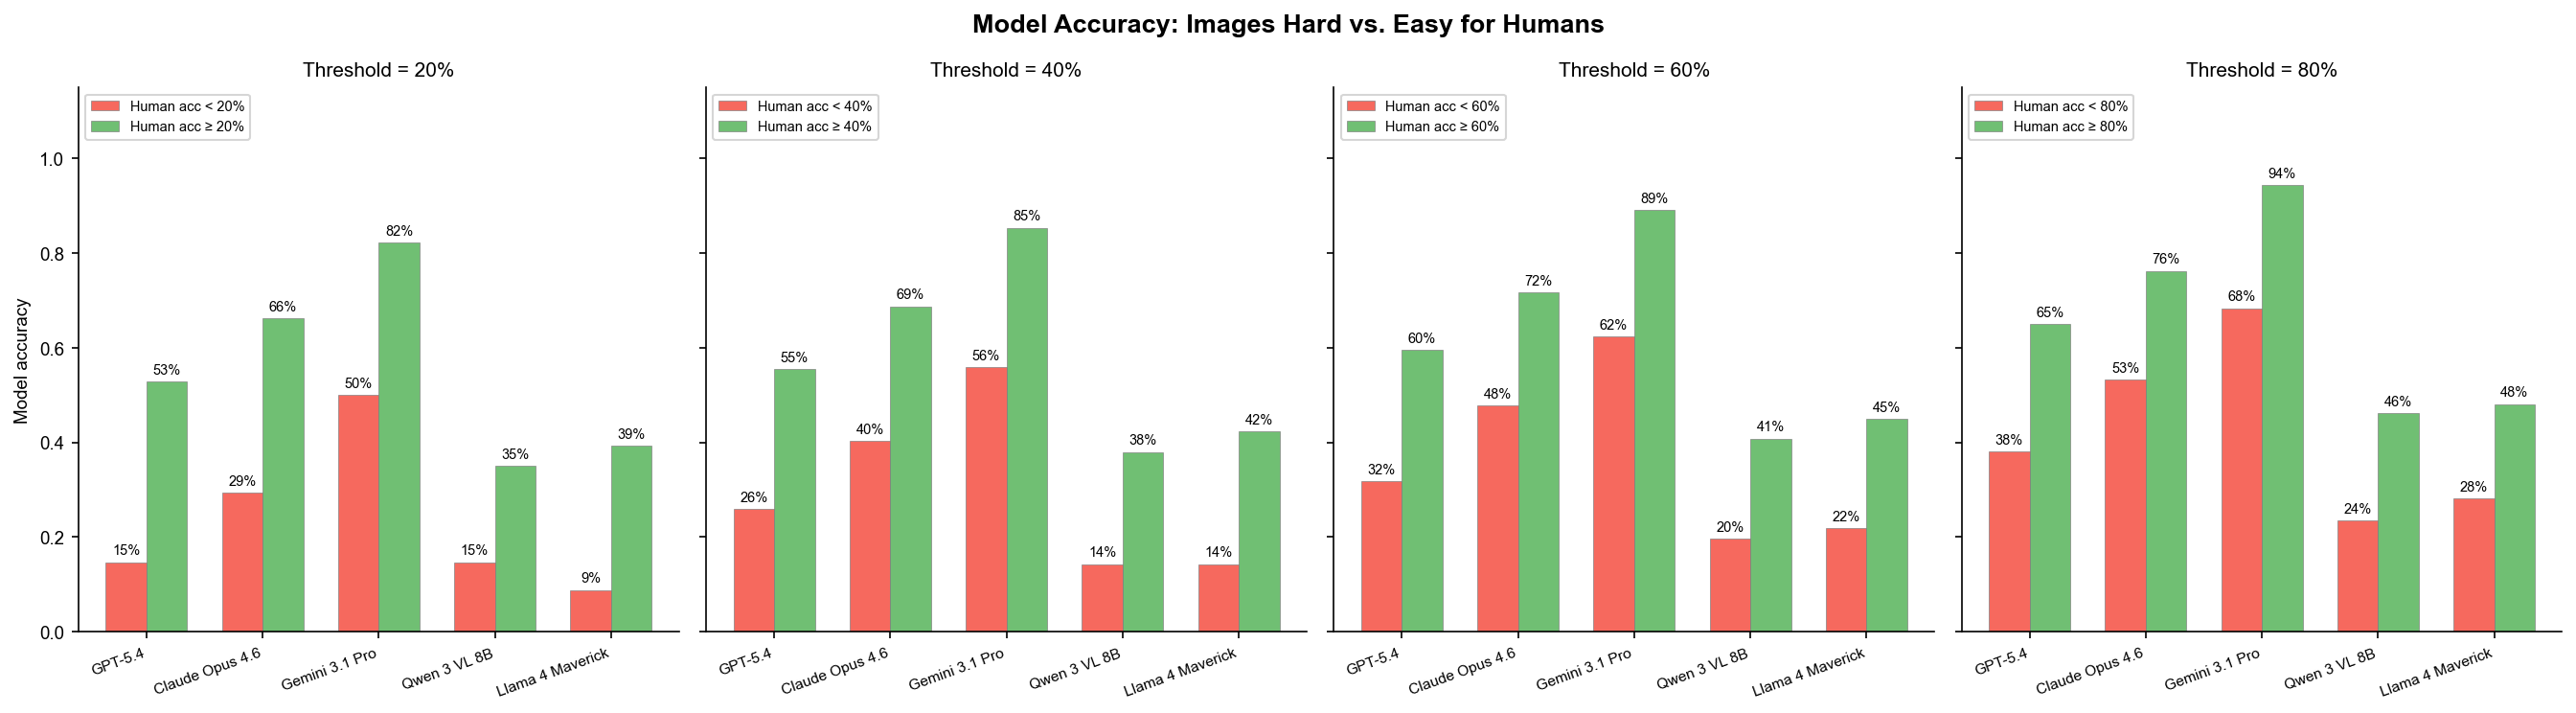

In [9]:
THRESHOLDS = [0.2, 0.4, 0.6, 0.8]

rows_thresh = []
for thresh in THRESHOLDS:
    hard_images = [img for img, acc in human_acc.items() if acc < thresh]
    easy_images = [img for img, acc in human_acc.items() if acc >= thresh]
    for model in MODELS:
        sub_hard = df[(df['model'] == model) & (df['image_id'].isin(hard_images))]
        sub_easy = df[(df['model'] == model) & (df['image_id'].isin(easy_images))]
        rows_thresh.append({
            'Model':      DISPLAY[model],
            'threshold':  thresh,
            'acc_hard':   sub_hard['correct'].mean() if len(sub_hard) else np.nan,
            'acc_easy':   sub_easy['correct'].mean() if len(sub_easy) else np.nan,
            'n_hard':     len(sub_hard),
            'n_easy':     len(sub_easy),
        })

thresh_df = pd.DataFrame(rows_thresh)

fig, axes = plt.subplots(1, len(THRESHOLDS), figsize=(4.5 * len(THRESHOLDS), 5), sharey=True)
fig.suptitle('Model Accuracy: Images Hard vs. Easy for Humans', fontsize=13, fontweight='bold')

for ax, thresh in zip(axes, THRESHOLDS):
    sub = thresh_df[thresh_df['threshold'] == thresh].set_index('Model').reindex(MODEL_ORDER)
    x = np.arange(len(MODEL_ORDER))
    w = 0.35
    bars_hard = ax.bar(x - w/2, sub['acc_hard'], width=w,
                       color='#F44336', alpha=0.8, label=f'Human acc < {int(thresh*100)}%',
                       edgecolor='grey', lw=0.4)
    bars_easy = ax.bar(x + w/2, sub['acc_easy'], width=w,
                       color='#4CAF50', alpha=0.8, label=f'Human acc ≥ {int(thresh*100)}%',
                       edgecolor='grey', lw=0.4)
    for bar in list(bars_hard) + list(bars_easy):
        h = bar.get_height()
        if not np.isnan(h):
            ax.text(bar.get_x() + bar.get_width()/2, h + 0.01,
                    f'{h:.0%}', ha='center', va='bottom', fontsize=7)
    ax.set_xticks(x)
    ax.set_xticklabels(MODEL_ORDER, rotation=20, ha='right', fontsize=7.5)
    ax.set_ylim(0, 1.15)
    ax.set_title(f'Threshold = {int(thresh*100)}%', fontsize=10)
    if ax is axes[0]:
        ax.set_ylabel('Model accuracy')
    ax.legend(fontsize=7, loc='upper left')

plt.tight_layout()
plt.savefig('data/figures/human_model_corr_hard_vs_easy.pdf', bbox_inches='tight')
plt.show()

## 7. Summary Table

In [10]:
summary_rows = []
for model in MODELS:
    sub = df[df['model'] == model][['human_acc', 'correct']].dropna()
    r, p = stats.pointbiserialr(sub['correct'].astype(int), sub['human_acc'])
    hard = sub[sub['human_acc'] < 0.4]['correct'].mean()
    easy = sub[sub['human_acc'] >= 0.6]['correct'].mean()
    summary_rows.append({
        'Model':               DISPLAY[model],
        'Overall acc':         sub['correct'].mean(),
        'Acc (human hard <40%)': hard,
        'Acc (human easy ≥60%)': easy,
        'Easy–Hard gap':       easy - hard,
        'r (corr w/ human)':   r,
        'p':                   p,
        'sig':                 '***' if p < 0.001 else '**' if p < 0.01 else '*' if p < 0.05 else 'ns',
    })

sum_df = pd.DataFrame(summary_rows)
pd.set_option('display.float_format', '{:.3f}'.format)
pd.set_option('display.max_columns', None)
pd.set_option('display.width', 200)
print(sum_df.to_string(index=False))

           Model  Overall acc  Acc (human hard <40%)  Acc (human easy ≥60%)  Easy–Hard gap  r (corr w/ human)     p sig
         GPT-5.4        0.495                  0.260                  0.596          0.336              0.323 0.000 ***
 Claude Opus 4.6        0.630                  0.403                  0.717          0.314              0.282 0.000 ***
  Gemini 3.1 Pro        0.794                  0.558                  0.892          0.333              0.364 0.000 ***
    Qwen 3 VL 8B        0.332                  0.143                  0.408          0.265              0.249 0.000 ***
Llama 4 Maverick        0.366                  0.143                  0.450          0.307              0.284 0.000 ***
